# UKF y EKF · modelos S y G/F · sólo CO2
Cuatro combinaciones con química congelada del16(G/F) y17(S/Kie fijo), LAB019–021 y016–018. Se reproducen EKF02/03 sin recalibración; mismas ventanas causales30min, regla de admisión, temperatura causal, iniciales, pulsos, gas y fuentes de ruido. Offline sólo contraste. Estos ensayos son evaluación retrospectiva, no validación ciega.
UKF escalado: alpha1,beta2,kappa0; n7(G/F),n6(S), lambda0, 15/13 puntos; peso central media0, covarianza2, restantes1/(2n). Raíz por autovalores semidefinida, sin jitter: tolera Cd/acumulador varianza cero. Autovalores negativos sólo por redondeo se truncan, negativos materiales fallan. No se aumentan estados con ruido: Qd local aditivo= L Qc L^T dt igual al EKF. R=.04². Cada modelo conserva su P0; var(G+F)=var(S)=25. En S permanecen dos fuentes independientes de ruido de consumo, no se reduce Q arbitrariamente.
Puntos sigma: proyección a dominio físico antes del RHS y en etapas RK4/paso1min, Cd<=1.5, resto no negativo. Se reconstruyen media y covarianza con los puntos efectivamente propagados; se registra sesgo de media y cambio de covarianza al proyectar inicialmente, y recortes por estado durante propagación. Actualización con medición lineal del acumulador y Joseph; media posterior recortada, P posterior conserva aproximación sin truncamiento exacto, igual a los EKF. Reinicio exacto del acumulador tras cada ventana (media y fila/columna de P cero).
La proyección es una aproximación que puede sesgar estimaciones cerca de cero; muchos recortes limitan la interpretación. El ruido de proceso se añade tras la transformación, como el Q local del EKF; la restricción no convierte esa distribución gaussiana en una distribución física exacta. No se interpreta menor número de recortes entre dimensiones como garantía de superioridad.
E0=10.010194g/L sigma2 en todos, como escenario sin etanol inicial medido. Muestras offline y densidad reservadas; NUT/GF sustituido excluidos de RMSE químico igual que03. No se reconstruye G/F del modelo S. Parámetros, matrices y sigma elegidos antes de evaluar, sin ajuste al holdout.

Los CSV registran recortes sigma por modelo/LAB/tiempo/estado y recortes posteriores por filtro; cambios menores a1e-12 en unidades físicas no cuentan en el registro UKF. Los recortes EKF conservan el criterio previo para reproducir sus conteos.


In [1]:
from IPython.utils.capture import capture_output
# Definiciones congeladas y preparación de datos, visibles para auditoría.
with capture_output():
 from pathlib import Path
 from dataclasses import replace
 import sys,json,hashlib,math,time
 import numpy as np,pandas as pd
 import matplotlib.pyplot as plt
 from scipy.integrate import solve_ivp
 from scipy.optimize import least_squares,minimize_scalar
 from IPython.display import display
 ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
 assert Path(sys.prefix).name.lower()=='fermentation'
 sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
 from wine_fermentation import model as kin
 from wine_fermentation.data import natural_batches
 from wine_fermentation.models.historical.calibration import load
 from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
 NAME='04_ukf_ekf_both_models'
 protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009','notebooks'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
 hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
 data,training,profiles=natural_batches(ROOT)
 # Correcciones de recuento inicial indicadas por el usuario; originales conservados.
 INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
 initial_biomass_audit=[];corrected_training=[]
 for batch in training:
  if batch.batch in INITIAL_VIABLE_MCELLS_ML:
   count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
   ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
   obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
   initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
   batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
   mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
   assert mask.sum()==1
   data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
   assert batch.initials['X']==batch.observations['X'][ids[0]]
  corrected_training.append(batch)
 training=corrected_training
 assert len(initial_biomass_audit)==2
 display(pd.DataFrame(initial_biomass_audit))
 
 start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
 config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
 # Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
 KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
 KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
 start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
 KD0_ZENTENO_H=0.00044
 start['Kd0']=KD0_ZENTENO_H
 assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
 display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
 names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
 assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
 bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
 fixed={k:v for k,v in start.items() if k not in names}
 display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
 display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))
 
 diffs=[]
 bylab={b.batch:b for b in training}
 for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
  aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
  z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
 sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
 assert len(diffs)>0
 print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
 treated=[];audit=[];rules=[]
 for b in training:
  obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
  obs['N'][np.isfinite(old)&(old<=.020)]=0
  if b.batch=='LAB006':
   ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
   obs['N'][ids]=0;depletion=122.
  else:
   last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
   depletion=float(b.time[ids[0]])
  obs['N'][b.time>depletion+12]=np.nan
  for i in np.flatnonzero(np.isfinite(old)):
   audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
  assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
  treated.append(replace(b,observations=obs))
  rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
 audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
 def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
 def simulate(b,p):
  def rhs(t,y):
   out=np.asarray(kin.rhs(t,y,p,b))
   if y[2]<=0 or y[3]<=0:
    q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
    out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
   return out
  # Muestra previa al salto si coincide con la nutrición; dosis completa después.
  minimum=np.full(5,np.inf);jumps=[];events={}
  for tp,dose in b.pulses.get('N',()):
   assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
   if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
  times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
  for end in sorted(set([float(times[-1])]+list(events))):
   requested=times[(times>now)&(times<=end)]
   sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
   if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
   minimum=np.minimum(minimum,sol.y.min(axis=1))
   records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
   if end in events:
    before=state.copy();state[1]+=events[end]
    assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
    jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
  f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
  f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
  f.attrs['pulse_jumps']=jumps
  assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
  return f
 
 def with_jumps(f):
  extra=[];tt=[]
  for j in f.attrs['pulse_jumps']:
   if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
   extra.append(j['after']);tt.append(j['t'])
  if not extra:return f
  added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
  return pd.concat([f,added]).sort_index(kind='stable')
 
 support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
 NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0
 
 # Química congelada de la recalibración anterior; sin optimización en esta prueba.
 theta={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
 assert theta['Kn0']==start['Kn0'] and theta['Kd0']==KD0_ZENTENO_H
 assert all(theta[k]==v for k,v in fixed.items())
 print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2))
 print('Química fija: no se recalibra en esta prueba de activación.')
 traincurves={b.batch:simulate(b,theta) for b in treated}
 
 v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
 raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
 batches={};cores={};volumes={};caches={};activation={};entry=[]
 for lab in LABS:
  b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
  def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
  volumes[lab]=volume
  if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
  if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
  if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
  batches[lab]=b;f=simulate(b,theta);cores[lab]=f;f=with_jumps(f)
  tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
  rates=[]
  for t in tt:
   y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(theta,kin.temperature_at(b,t),*y)
   if y[2]<=0 or y[3]<=0:q['mu']=0.
   rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
  caches[lab]=(tt,np.asarray(rates))
  consumed=b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.GF)
  z=np.clip((consumed-5.)/5.,0.,1.);activation[lab]=z*z*(3.-2.*z)
  assert np.all(activation[lab][consumed<=5.]==0) and np.all(activation[lab][consumed>=10.]==1)
  entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
  obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
 display(pd.DataFrame(entry))
 CSAT=1.5
 def gas(lab,k,gain=1,activated=True):
  t,source=caches[lab]
  if activated:source=source*activation[lab]
  cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t));qout[0]=max(source[0]-k*CSAT,0)
  for i,dt in enumerate(np.diff(t),1):
   qp=(source[i-1]+source[i])/2;D=max(CSAT-cd[i-1],0)
   if qp<=0 or D<=0:delta=0.
   elif k*D<=qp:delta=D*(-np.expm1(-k*dt))
   else:
    crossing=(D-qp/k)/qp;linear=min(dt,crossing);delta=qp*linear
    if crossing<dt:delta+=(qp/k)*(-np.expm1(-k*(dt-crossing)))
   cd[i]=cd[i-1]+delta;acc[i]=delta/dt;qout[i]=qp-acc[i]
  assert cd.min()>=0 and cd.max()<=CSAT+1e-10 and qout.min()>-1e-10
  assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
  return pd.DataFrame(dict(qprod=source,Cd=cd,qgas=qout,qpred=gain*qout),index=t)
 # Pareja calibrada originalmente; activación5–10g/L, sin reajuste.
 KLA=0.07467887635557982;GAIN=0.635238911849421
 print('PARÁMETROS GAS',json.dumps(dict(kLa=KLA,gain=GAIN,Csat=CSAT,Cd0=0,training=TRAIN,holdout=HOLD,fit=False),indent=2))
 curves={lab:gas(lab,KLA,GAIN) for lab in LABS};metrics=[]
 for lab in LABS:
  o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
  metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
 metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())
 
 display(pd.DataFrame([dict(LAB=lab,inicio_5g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>0)[0]]),completa_10g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>=1)[0]])) for lab in LABS]))
SCALE_EKF=np.array([.3,.25,80.,80.,15.,.2,1.])
BASE_THETA=theta.copy();BASE_GAS=(KLA,GAIN)
print('Química fija:',json.dumps(theta,indent=2));print('kLa, ganancia:',KLA,GAIN)


Química fija: {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}
kLa, ganancia: 0.07467887635557982 0.635238911849421


In [2]:

ALPHA=1.;BETA=2.;KAPPA=0.
UKF_RESULTS={};SIGMA_LOG=[];UPDATE_LOG=[];PROJECTION_LOG=[]
def sigma_points(mean,P):
 n=len(mean);ev,U=np.linalg.eigh((P+P.T)/2);assert ev.min()>-1e-8,'Covarianza materialmente indefinida'
 B=(U*np.sqrt(n*np.maximum(ev,0)))
 points=np.vstack([mean,mean+B.T,mean-B.T]);wm=np.r_[0.,np.full(2*n,1/(2*n))];wc=wm.copy();wc[0]=2.
 assert np.max(abs(wm@points-mean))<1e-10
 d=points-mean;assert np.max(abs((d.T*wm)@d-P))<1e-7
 return points,wm,wc

def moments(points,wm,wc):
 m=wm@points;d=points-m;P=(d.T*wc)@d;return m,(P+P.T)/2

def propagate_sigma(points,start,end,Tfun,S0,scale,labels,model,lab):
 cd=len(scale)-2;w=points*scale;flags=np.zeros_like(w,dtype=bool);events=np.zeros(len(scale),int);maximum=np.zeros(len(scale))
 def project(a):
  target=np.maximum(a,0.);target[:,cd]=np.minimum(target[:,cd],1.5)
  distance=abs(target-a);hit=distance>1e-12
  flags[:]|=hit;events[:]+=hit.sum(axis=0);maximum[:]=np.maximum(maximum,distance.max(axis=0));return target
 before=w.copy();w=project(w);n=len(scale);wm=np.r_[0.,np.full(2*n,1/(2*n))];wc=wm.copy();wc[0]=2.
 mb,pb=moments(before/scale,wm,wc);ma,pa=moments(w/scale,wm,wc)
 PROJECTION_LOG.append(dict(modelo=model,LAB=lab,t_h=start,cambio_media_escalada=float(np.linalg.norm(ma-mb)),cambio_cov_escalada=float(np.linalg.norm(pa-pb))))
 count=max(1,int(np.ceil((end-start)*60-1e-7)));dt=(end-start)/count
 for j in range(count):
  t=start+j*dt
  k1=rates_ekf(w,t,Tfun(t),S0)
  k2=rates_ekf(project(w+dt*k1/2),t+dt/2,Tfun(t+dt/2),S0)
  k3=rates_ekf(project(w+dt*k2/2),t+dt/2,Tfun(t+dt/2),S0)
  k4=rates_ekf(project(w+dt*k3),t+dt,Tfun(t+dt),S0)
  w=project(w+dt*(k1+2*k2+2*k3+k4)/6)
 for k in np.flatnonzero(flags.any(axis=0)):
  SIGMA_LOG.append(dict(modelo=model,LAB=lab,t_inicio_h=start,t_fin_h=end,estado=labels[k],puntos_recortados=int(flags[:,k].sum()),eventos_etapas=int(events[k]),max_correccion_unidad_fisica=float(maximum[k])))
 return w/scale

def run_ukf(reference,model):
 scale=SCALE_EKF.copy();n=len(scale);cd=n-2;acc=n-1;physical=['X','N','G','F','E','Cd'] if n==7 else ['X','N','GF','E','Cd'];labels=physical+['Acumulador'];out={}
 for lab in LABS:
  batch=batches[lab];horizon=float(v.horizons[lab]);f0=reference[lab]['frame'];initial=np.array([f0['Libre_'+k].iloc[0] for k in physical]);S0=batch.initials['G']+batch.initials['F']
  if n==7:
   P=np.diag([max(.03,.2*initial[0])**2,.015**2,12.5,37.5,4,0.,0.]);P[2,3]=P[3,2]=-12.5
   if lab in HOLD:
    r=initial[2]/S0;P[2,2]=r*r*25+25;P[3,3]=(1-r)**2*25+25;P[2,3]=P[3,2]=r*(1-r)*25-25
  else:P=np.diag([max(.03,.2*initial[0])**2,.015**2,25.,4.,0.,0.])
  z=np.r_[initial,0.]/scale;P=P/np.outer(scale,scale)
  rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int);temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;values=temp.to_numpy(float)
  def Tfun(t,available=available,values=values):
   j=np.searchsorted(available,t+1e-12,side='right')-1;assert j>=0 and available[j]<=t+1e-10;return float(values[j])
  sensor=reference[lab]['sensor'];timegrid=f0.t_h.to_numpy();events={round(t,10):d for t,d in batch.pulses['N']};records=[];forecasts=[];diag=[]
  for i,t in enumerate(timegrid):
   if i:
    start=timegrid[i-1];dt=t-start;before=z.copy();points,wm,wc=sigma_points(z,P)
    propagated=propagate_sigma(points,start,t,Tfun,S0,scale,labels,model,lab);z,P=moments(propagated,wm,wc)
    P+=noise_matrix(before*scale,Tfun(start),S0)*dt;P=(P+P.T)/2
   if t in events:z[1]+=events[t]/scale[1]
   if t>0 and abs(t/.5-round(t/.5))<1e-8:
    o=sensor.iloc[round(t/.5)-1];prediction=z[acc]/.5;forecasts.append(dict(t_h=t,measured=o.measured,forecast=prediction,valid=o.valid,assimilate=o.assimilate))
    if o.assimilate:
     H=np.zeros(n);H[acc]=2.;innovation_var=float(H@P@H+R_CO2);K=P@H/innovation_var;innovation=o.measured-prediction
     updated=z+K*innovation;projected=np.maximum(updated,0);projected[cd]=min(projected[cd],1.5/scale[cd]);hit=abs(projected-updated)*scale>1e-12
     B=np.eye(n)-np.outer(K,H);P=B@P@B.T+np.outer(K,K)*R_CO2;P=(P+P.T)/2;z=projected
     diag.append(dict(t_h=t,innovation=innovation,NIS=innovation**2/innovation_var,recortes=int(hit[:-1].sum())))
     for k in np.flatnonzero(hit):UPDATE_LOG.append(dict(filtro='UKF',modelo=model,LAB=lab,t_h=t,estado=labels[k],antes=float(updated[k]*scale[k]),despues=float(projected[k]*scale[k])))
    z[acc]=0.;P[acc,:]=0.;P[:,acc]=0.
   assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>-1e-7
   assert z[cd]*scale[cd]<=1.5+1e-10 and z.min()>-1e-10
   records.append(np.r_[t,z[:-1]*scale[:-1]])
  frame=pd.DataFrame(records,columns=['t_h']+['EKF_'+k for k in physical])
  if n==7:frame['EKF_GF']=frame.EKF_G+frame.EKF_F
  out[lab]=dict(frame=frame,sensor=pd.DataFrame(forecasts),diag=pd.DataFrame(diag))
  print('UKF',model,lab,'completado',len(diag),'actualizaciones, recortes posterior',sum(d['recortes'] for d in diag),flush=True)
 return out
# Verificación determinista de transformada afín y covarianza singular.
for dimension in [6,7]:
 mean=np.linspace(.2,1.,dimension);Ptest=np.diag(np.r_[np.linspace(.01,.1,dimension-2),0.,0.]);points,wm,wc=sigma_points(mean,Ptest)
 A=np.eye(dimension)*1.2;A[0,1]=.3;b=np.ones(dimension)*.1
 m,C=moments(points@A.T+b,wm,wc)
 assert np.allclose(m,A@mean+b) and np.allclose(C,A@Ptest@A.T)
print('Puntos sigma 13/15, momentos y transformación afín con covarianza singular comprobados.')


Puntos sigma 13/15, momentos y transformación afín con covarianza singular comprobados.


## Modelo G/F: reproducción EKF02 y UKF con el mismo modelo

In [3]:

def rates_ekf(w,t,T,S0):
 x,n,g,f,e,cd=np.maximum(w[:,:6],0.).T;tk=T+273.15;R=8.314
 am=np.exp(59453*(tk-300)/(300*R*tk));ab=np.exp(11000*(tk-296.15)/(296.15*R*tk));ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=theta['mu0']*am*n/(n+theta['Kn0']*ak+1e-8);mu=np.where((g<=0)|(f<=0),0.,mu)
 bg=theta['betaG0']*ab*g/(g+theta['Kg0']*ak+1e-8)/(1+e/(theta['Kie0']*(ak+1e-8)))
 bf=theta['betaF0']*ab*f/(f+theta['Kf0']*ak+1e-8)/(1+g/(theta['Kig0']*(ak+1e-8)))/(1+e/(theta['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=np.where(tk>=td,theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)),0.)
 m=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*(g+f+1e-8)/(g+f+1+1e-8)
 z=np.clip((S0-g-f-5)/5,0,1);A=z*z*(3-2*z)
 qp=A*(mu/12.72+(bg+bf)/1.05)*x
 acc=np.minimum(qp,KLA*np.maximum(1.5-cd,0));gas=qp-acc
 return np.column_stack([(mu-kd)*x,-mu*x/theta['Yxn'],-(mu/theta['Yxg']+bg/theta['Yeg']+m*g/(g+f+1e-8))*x,-(mu/theta['Yxf']+bf/theta['Yef']+m*f/(g+f+1e-8))*x,(bg+bf)*x,acc,GAIN*gas])

def transition(z,start,end,Tfun,S0,step=1/60):
 w=np.atleast_2d(z)*SCALE_EKF;n=max(1,int(np.ceil((end-start)/step-1e-7)));dt=(end-start)/n
 for j in range(n):
  t=start+j*dt
  k1=rates_ekf(w,t,Tfun(t),S0);k2=rates_ekf(w+dt*k1/2,t+dt/2,Tfun(t+dt/2),S0)
  k3=rates_ekf(w+dt*k2/2,t+dt/2,Tfun(t+dt/2),S0);k4=rates_ekf(w+dt*k3,t+dt,Tfun(t+dt),S0)
  w+=dt*(k1+2*k2+2*k3+k4)/6
  w=np.maximum(w,0);w[:,5]=np.minimum(w[:,5],1.5)
 return w/SCALE_EKF

def jacobian(z,start,end,Tfun,S0):
 eps=1e-5;delta=np.eye(7)*eps;lower=z-delta
 den=np.where(z>=eps,2*eps,eps)
 for j in range(7):
  if z[j]<eps:lower[j]=z
 out=transition(np.vstack([z,z+delta,lower]),start,end,Tfun,S0)
 J=((out[1:8]-out[8:])/den[:,None]).T
 return out[0],J

def noise_matrix(state,T,S0):
 # Flux mapping through the active accumulation/emission branch.
 x,n,g,f,e,cd=state[:6];z=np.clip((S0-g-f-5)/5,0,1);A=z*z*(3-2*z)
 qp=float(rates_ekf(np.array([state]),0,T,S0)[0,5]+rates_ekf(np.array([state]),0,T,S0)[0,6]/GAIN)
 dissolved=float(qp<KLA*max(1.5-cd,0))
 L=np.zeros((7,4));L[:5,0]=[1,-1/theta['Yxn'],-1/theta['Yxg'],-1/theta['Yxf'],0]
 L[2,1]=-1;L[4,1]=theta['Yeg'];L[3,2]=-1;L[4,2]=theta['Yef']
 production=A*np.array([1/12.72,theta['Yeg']/1.05,theta['Yef']/1.05,1])
 L[5]=dissolved*production;L[6]=GAIN*(1-dissolved)*production
 return (L@np.diag(np.array([.003,.08,.08,.01])**2)@L.T)/np.outer(SCALE_EKF,SCALE_EKF)

R_CO2=.04**2
RESULTS={};initial_audit=[];sensor_audit=[]
for lab in LABS:
 batch=batches[lab];horizon=float(v.horizons[lab]);rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
 temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;values=temp.to_numpy(float)
 def Tfun(t,available=available,values=values):
  j=np.searchsorted(available,t+1e-12,side='right')-1
  assert j>=0 and available[j]<=t+1e-10
  return float(values[j])
 rawg=v.raw_co2[lab].copy();rawg['bin']=np.ceil(rawg.t_h/.5-1e-10).astype(int)
 rows=[]
 for end in np.arange(.5,horizon+1e-9,.5):
  g0=rawg.loc[rawg.bin.eq(round(end/.5))].dropna(subset=['flow_sccm']);gaps=np.diff(np.r_[end-.5,g0.t_h.to_numpy(),end])
  factor=44.0095*60*.74/(1000*24.16)
  yy=g0.flow_sccm.to_numpy()*factor/volumes[lab](g0.t_h.to_numpy())
  valid=len(g0)>=30 and gaps.max()<=2/60
  rows.append(dict(t_h=end,y=float(np.mean(yy)) if len(yy) else np.nan,valid=valid))
 sensor=pd.DataFrame(rows);sensor['assimilate']=sensor.valid&sensor.y.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.y.shift().ge(.05)
 sensor_audit.append(dict(LAB=lab,ventanas=len(sensor),asimiladas=int(sensor.assimilate.sum())))
 initial=np.array([batch.initials[k] for k in kin.STATE_NAMES]+[0.]);initial[4]=10.010194;S0=initial[2]+initial[3]
 P=np.diag([max(.03,.2*initial[0])**2,.015**2,12.5,37.5,4,0.,0.]);P[2,3]=P[3,2]=-12.5
 if lab in HOLD:
  r=initial[2]/S0;P[2,2]=r*r*25+25;P[3,3]=(1-r)**2*25+25;P[2,3]=P[3,2]=r*(1-r)*25-25
 initial_audit.append(dict(LAB=lab,**dict(zip(kin.STATE_NAMES,initial[:5])),sigma_X=np.sqrt(P[0,0]),sigma_GF=np.sqrt(P[2,2]+P[3,3]+2*P[2,3])))
 z=np.r_[initial,0.]/SCALE_EKF;free=z.copy();P=P/np.outer(SCALE_EKF,SCALE_EKF)
 timegrid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,[t for t,d in batch.pulses['N']]],10))
 events={round(t,10):d for t,d in batch.pulses['N']};records=[];forecasts=[];diag=[];snap=[]
 for i,t in enumerate(timegrid):
  if i:
   start=timegrid[i-1];dt=t-start;before=z.copy();z,J=jacobian(z,start,t,Tfun,S0)
   W=noise_matrix(before*SCALE_EKF,Tfun(start),S0)*dt
   P=J@P@J.T+W;P=(P+P.T)/2
   free=transition(free,start,t,Tfun,S0)[0]
  if t in events:z[1]+=events[t]/SCALE_EKF[1];free[1]+=events[t]/SCALE_EKF[1]
  if t>0 and abs(t/.5-round(t/.5))<1e-8:
   o=sensor.iloc[round(t/.5)-1];prediction=z[6]/.5;predfree=free[6]/.5
   forecasts.append(dict(t_h=t,measured=o.y,forecast=prediction,free=predfree,valid=o.valid,assimilate=o.assimilate))
   if o.assimilate:
    H=np.zeros(7);H[6]=2.;S=float(H@P@H+R_CO2);K=P@H/S;innovation=o.y-prediction
    updated=z+K*innovation;clipped=int(np.sum(updated[:6]<0)+int(updated[5]*SCALE_EKF[5]>1.5))
    projected_log=np.maximum(updated,0.);projected_log[5]=min(projected_log[5],1.5/SCALE_EKF[5])
    labels_log=['X', 'N', 'G', 'F', 'E', 'Cd', 'Acumulador']
    for k_log in np.flatnonzero(projected_log!=updated):
     UPDATE_LOG.append(dict(filtro='EKF',modelo='GF',LAB=lab,t_h=t,estado=labels_log[k_log],antes=float(updated[k_log]*SCALE_EKF[k_log]),despues=float(projected_log[k_log]*SCALE_EKF[k_log])))
    B=np.eye(7)-np.outer(K,H);P=B@P@B.T+np.outer(K,K)*R_CO2;P=(P+P.T)/2
    z=np.maximum(updated,0);z[5]=min(z[5],1.5/SCALE_EKF[5])
    diag.append(dict(t_h=t,innovation=innovation,NIS=innovation**2/S,recortes=clipped))
   z[6]=0.;free[6]=0.;P[6,:]=0.;P[:,6]=0.
  assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>-1e-7
  records.append(np.r_[t,z[:6]*SCALE_EKF[:6],free[:6]*SCALE_EKF[:6]]);snap.append(np.diag(P)[:6]*SCALE_EKF[:6]**2)
 frame=pd.DataFrame(records,columns=['t_h']+['EKF_'+k for k in ['X','N','G','F','E','Cd']]+['Libre_'+k for k in ['X','N','G','F','E','Cd']])
 for prefix in ['EKF_','Libre_']:frame[prefix+'GF']=frame[prefix+'G']+frame[prefix+'F']
 RESULTS[lab]=dict(frame=frame,sensor=pd.DataFrame(forecasts),diag=pd.DataFrame(diag),variance=np.array(snap))
 print(lab,'terminado, correcciones',len(diag),'recortes',sum(d['recortes'] for d in diag),flush=True)
display(pd.DataFrame(initial_audit));display(pd.DataFrame(sensor_audit))

RESULTS_GF=RESULTS;SCALE_GF=SCALE_EKF.copy();THETA_GF=theta.copy()

UKF_GF=run_ukf(RESULTS_GF,'GF')


LAB019 terminado, correcciones 217 recortes 76
LAB020 terminado, correcciones 223 recortes 19
LAB021 terminado, correcciones 166 recortes 26
LAB016 terminado, correcciones 249 recortes 212
LAB017 terminado, correcciones 213 recortes 216
LAB018 terminado, correcciones 237 recortes 253
UKF GF LAB019 completado 217 actualizaciones, recortes posterior 0
UKF GF LAB020 completado 223 actualizaciones, recortes posterior 0
UKF GF LAB021 completado 166 actualizaciones, recortes posterior 0
UKF GF LAB016 completado 249 actualizaciones, recortes posterior 0
UKF GF LAB017 completado 213 actualizaciones, recortes posterior 0
UKF GF LAB018 completado 237 actualizaciones, recortes posterior 0


,LAB,X,N,G,F,E,sigma_X,sigma_GF
0,LAB019,0.283162,0.230025,79.190000,78.970000,10.010194,0.056632,5.0
1,LAB020,0.153342,0.225556,77.940000,79.520000,10.010194,0.030668,5.0
2,LAB021,0.270000,0.231202,80.190000,81.040000,10.010194,0.054000,5.0
3,LAB016,0.390000,0.214330,84.158815,88.341185,10.010194,0.078000,5.0
4,LAB017,0.390000,0.214330,84.158815,88.341185,10.010194,0.078000,5.0
5,LAB018,0.390000,0.214330,84.158815,88.341185,10.010194,0.078000,5.0


,LAB,ventanas,asimiladas
0,LAB019,332,217
1,LAB020,344,223
2,LAB021,332,166
3,LAB016,302,249
4,LAB017,282,213
5,LAB018,282,237


## Modelo S: reproducción EKF03 y UKF con el mismo modelo

In [4]:

# Parámetros de la ejecución17 con Kie0 fijo, sin recalibración.
PS={'mu0':0.09085058816701197,'betaS0':0.8189664538991809,'Ks0':23.046564567082594,'Kie0':96.26516563486751,'Yxn':6.497331613020979,'Yes':0.4893180893478443}
YXS=1/(1/theta['Yxg']+1/theta['Yxf']);SCALE_EKF=np.array([.3,.25,160.,15.,.2,1.])
assert PS['Kie0']==theta['Kie0']
print('Parámetros químicos S congelados',json.dumps(PS,indent=2))
def rates_ekf(w,t,T,S0):
 x,n,s,e,cd=np.maximum(w[:,:5],0.).T;tk=T+273.15;R=8.314
 am=np.exp(59453*(tk-300)/(300*R*tk));ab=np.exp(11000*(tk-296.15)/(296.15*R*tk));ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=PS['mu0']*am*n/(n+theta['Kn0']*ak+1e-8);mu=np.where(s<=0,0.,mu)
 be=PS['betaS0']*ab*s/(s+PS['Ks0']*ak+1e-8)/(1+e/(PS['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=np.where(tk>=td,theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)),0.)
 m=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*s/(s+1.)
 z=np.clip((S0-s-5)/5,0,1);A=z*z*(3-2*z);qp=A*(mu/12.72+be/1.05)*x
 acc=np.minimum(qp,KLA*np.maximum(1.5-cd,0));gas=qp-acc
 return np.column_stack([(mu-kd)*x,-mu*x/PS['Yxn'],-(mu/YXS+be/PS['Yes']+m)*x,be*x,acc,GAIN*gas])
def transition(z,start,end,Tfun,S0,step=1/60):
 w=np.atleast_2d(z)*SCALE_EKF;n=max(1,int(np.ceil((end-start)/step-1e-7)));dt=(end-start)/n
 for j in range(n):
  t=start+j*dt
  k1=rates_ekf(w,t,Tfun(t),S0);k2=rates_ekf(w+dt*k1/2,t+dt/2,Tfun(t+dt/2),S0)
  k3=rates_ekf(w+dt*k2/2,t+dt/2,Tfun(t+dt/2),S0);k4=rates_ekf(w+dt*k3,t+dt,Tfun(t+dt),S0)
  w+=dt*(k1+2*k2+2*k3+k4)/6
  w=np.maximum(w,0);w[:,4]=np.minimum(w[:,4],1.5)
 return w/SCALE_EKF

def jacobian(z,start,end,Tfun,S0):
 eps=1e-5;delta=np.eye(6)*eps;lower=z-delta
 den=np.where(z>=eps,2*eps,eps)
 for j in range(6):
  if z[j]<eps:lower[j]=z
 out=transition(np.vstack([z,z+delta,lower]),start,end,Tfun,S0)
 J=((out[1:7]-out[7:])/den[:,None]).T
 return out[0],J


def noise_matrix(state,T,S0):
 x,n,s,e,cd=state[:5];z=np.clip((S0-s-5)/5,0,1);A=z*z*(3-2*z)
 rates=rates_ekf(np.array([state]),0,T,S0)[0];qp=float(rates[4]+rates[5]/GAIN)
 dissolved=float(qp<KLA*max(1.5-cd,0));L=np.zeros((6,4))
 L[:4,0]=[1,-1/PS['Yxn'],-1/YXS,0]
 L[2,1:3]=-1;L[3,1:3]=PS['Yes']
 production=A*np.array([1/12.72,PS['Yes']/1.05,PS['Yes']/1.05,1])
 L[4]=dissolved*production;L[5]=GAIN*(1-dissolved)*production
 return (L@np.diag(np.array([.003,.08,.08,.01])**2)@L.T)/np.outer(SCALE_EKF,SCALE_EKF)
R_CO2=.04**2
RESULTS={};initial_audit=[];sensor_audit=[]
for lab in LABS:
 batch=batches[lab];horizon=float(v.horizons[lab]);rawt=v.raw_temperature[lab].copy();rawt['minute']=np.floor(rawt.t_h*60).astype(int)
 temp=rawt.groupby('minute')['T'].median().dropna();available=(temp.index.to_numpy()+1)/60;values=temp.to_numpy(float)
 def Tfun(t,available=available,values=values):
  j=np.searchsorted(available,t+1e-12,side='right')-1
  assert j>=0 and available[j]<=t+1e-10
  return float(values[j])
 rawg=v.raw_co2[lab].copy();rawg['bin']=np.ceil(rawg.t_h/.5-1e-10).astype(int)
 rows=[]
 for end in np.arange(.5,horizon+1e-9,.5):
  g0=rawg.loc[rawg.bin.eq(round(end/.5))].dropna(subset=['flow_sccm']);gaps=np.diff(np.r_[end-.5,g0.t_h.to_numpy(),end])
  factor=44.0095*60*.74/(1000*24.16)
  yy=g0.flow_sccm.to_numpy()*factor/volumes[lab](g0.t_h.to_numpy())
  valid=len(g0)>=30 and gaps.max()<=2/60
  rows.append(dict(t_h=end,y=float(np.mean(yy)) if len(yy) else np.nan,valid=valid))
 sensor=pd.DataFrame(rows);sensor['assimilate']=sensor.valid&sensor.y.ge(.05)&sensor.valid.shift(fill_value=False)&sensor.y.shift().ge(.05)
 sensor_audit.append(dict(LAB=lab,ventanas=len(sensor),asimiladas=int(sensor.assimilate.sum())))
 initial=np.array([batch.initials['X'],batch.initials['N'],batch.initials['G']+batch.initials['F'],10.010194,0.]);S0=initial[2]
 P=np.diag([max(.03,.2*initial[0])**2,.015**2,25.,4.,0.,0.])
 initial_audit.append(dict(LAB=lab,X0=initial[0],N0=initial[1],S0=S0,E0=initial[3],sigma_S=np.sqrt(P[2,2])))
 z=np.r_[initial,0.]/SCALE_EKF;free=z.copy();P=P/np.outer(SCALE_EKF,SCALE_EKF)
 timegrid=np.unique(np.round(np.r_[np.arange(0,horizon,1/12),sensor.t_h,horizon,[t for t,d in batch.pulses['N']]],10))
 events={round(t,10):d for t,d in batch.pulses['N']};records=[];forecasts=[];diag=[];snap=[]
 for i,t in enumerate(timegrid):
  if i:
   start=timegrid[i-1];dt=t-start;before=z.copy();z,J=jacobian(z,start,t,Tfun,S0)
   W=noise_matrix(before*SCALE_EKF,Tfun(start),S0)*dt
   P=J@P@J.T+W;P=(P+P.T)/2
   free=transition(free,start,t,Tfun,S0)[0]
  if t in events:z[1]+=events[t]/SCALE_EKF[1];free[1]+=events[t]/SCALE_EKF[1]
  if t>0 and abs(t/.5-round(t/.5))<1e-8:
   o=sensor.iloc[round(t/.5)-1];prediction=z[5]/.5;predfree=free[5]/.5
   forecasts.append(dict(t_h=t,measured=o.y,forecast=prediction,free=predfree,valid=o.valid,assimilate=o.assimilate))
   if o.assimilate:
    H=np.zeros(6);H[5]=2.;S=float(H@P@H+R_CO2);K=P@H/S;innovation=o.y-prediction
    updated=z+K*innovation;clipped=int(np.sum(updated[:5]<0)+int(updated[4]*SCALE_EKF[4]>1.5))
    projected_log=np.maximum(updated,0.);projected_log[4]=min(projected_log[4],1.5/SCALE_EKF[4])
    labels_log=['X', 'N', 'GF', 'E', 'Cd', 'Acumulador']
    for k_log in np.flatnonzero(projected_log!=updated):
     UPDATE_LOG.append(dict(filtro='EKF',modelo='S',LAB=lab,t_h=t,estado=labels_log[k_log],antes=float(updated[k_log]*SCALE_EKF[k_log]),despues=float(projected_log[k_log]*SCALE_EKF[k_log])))
    B=np.eye(6)-np.outer(K,H);P=B@P@B.T+np.outer(K,K)*R_CO2;P=(P+P.T)/2
    z=np.maximum(updated,0);z[4]=min(z[4],1.5/SCALE_EKF[4])
    diag.append(dict(t_h=t,innovation=innovation,NIS=innovation**2/S,recortes=clipped))
   z[5]=0.;free[5]=0.;P[5,:]=0.;P[:,5]=0.
  assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>-1e-7
  records.append(np.r_[t,z[:5]*SCALE_EKF[:5],free[:5]*SCALE_EKF[:5]]);snap.append(np.diag(P)[:5]*SCALE_EKF[:5]**2)
 frame=pd.DataFrame(records,columns=['t_h']+['EKF_'+k for k in ['X','N','GF','E','Cd']]+['Libre_'+k for k in ['X','N','GF','E','Cd']])
 RESULTS[lab]=dict(frame=frame,sensor=pd.DataFrame(forecasts),diag=pd.DataFrame(diag),variance=np.array(snap))
 print(lab,'terminado, correcciones',len(diag),'recortes',sum(d['recortes'] for d in diag),flush=True)
display(pd.DataFrame(initial_audit));display(pd.DataFrame(sensor_audit))

RESULTS_S=RESULTS;UKF_S=run_ukf(RESULTS_S,'S')


Parámetros químicos S congelados {
  "mu0": 0.09085058816701197,
  "betaS0": 0.8189664538991809,
  "Ks0": 23.046564567082594,
  "Kie0": 96.26516563486751,
  "Yxn": 6.497331613020979,
  "Yes": 0.4893180893478443
}
LAB019 terminado, correcciones 217 recortes 61
LAB020 terminado, correcciones 223 recortes 9
LAB021 terminado, correcciones 166 recortes 41
LAB016 terminado, correcciones 249 recortes 83
LAB017 terminado, correcciones 213 recortes 87
LAB018 terminado, correcciones 237 recortes 90
UKF S LAB019 completado 217 actualizaciones, recortes posterior 0
UKF S LAB020 completado 223 actualizaciones, recortes posterior 0
UKF S LAB021 completado 166 actualizaciones, recortes posterior 0
UKF S LAB016 completado 249 actualizaciones, recortes posterior 0
UKF S LAB017 completado 213 actualizaciones, recortes posterior 7
UKF S LAB018 completado 237 actualizaciones, recortes posterior 0


,LAB,X0,N0,S0,E0,sigma_S
0,LAB019,0.283162,0.230025,158.16,10.010194,5.0
1,LAB020,0.153342,0.225556,157.46,10.010194,5.0
2,LAB021,0.270000,0.231202,161.23,10.010194,5.0
3,LAB016,0.390000,0.214330,172.50,10.010194,5.0
4,LAB017,0.390000,0.214330,172.50,10.010194,5.0
5,LAB018,0.390000,0.214330,172.50,10.010194,5.0


,LAB,ventanas,asimiladas
0,LAB019,332,217
1,LAB020,344,223
2,LAB021,332,166
3,LAB016,302,249
4,LAB017,282,213
5,LAB018,282,237


## Comparación reservada y auditoría de recortes

METRICS_JSON [{"LAB":"LAB019","variable":"CO2","caso":"EKF GF","n":332,"RMSE":0.070046655},{"LAB":"LAB019","variable":"CO2","caso":"UKF GF","n":332,"RMSE":0.0702477776},{"LAB":"LAB019","variable":"CO2","caso":"EKF S","n":332,"RMSE":0.0630814324},{"LAB":"LAB019","variable":"CO2","caso":"UKF S","n":332,"RMSE":0.0614805069},{"LAB":"LAB020","variable":"CO2","caso":"EKF GF","n":344,"RMSE":0.066491978},{"LAB":"LAB020","variable":"CO2","caso":"UKF GF","n":344,"RMSE":0.0785799879},{"LAB":"LAB020","variable":"CO2","caso":"EKF S","n":344,"RMSE":0.065001463},{"LAB":"LAB020","variable":"CO2","caso":"UKF S","n":344,"RMSE":0.0715538169},{"LAB":"LAB021","variable":"CO2","caso":"EKF GF","n":332,"RMSE":0.0856779359},{"LAB":"LAB021","variable":"CO2","caso":"UKF GF","n":332,"RMSE":0.0908545118},{"LAB":"LAB021","variable":"CO2","caso":"EKF S","n":332,"RMSE":0.1020209526},{"LAB":"LAB021","variable":"CO2","caso":"UKF S","n":332,"RMSE":0.1044030456},{"LAB":"LAB016","variable":"CO2","caso":"EKF GF","n":302,"R

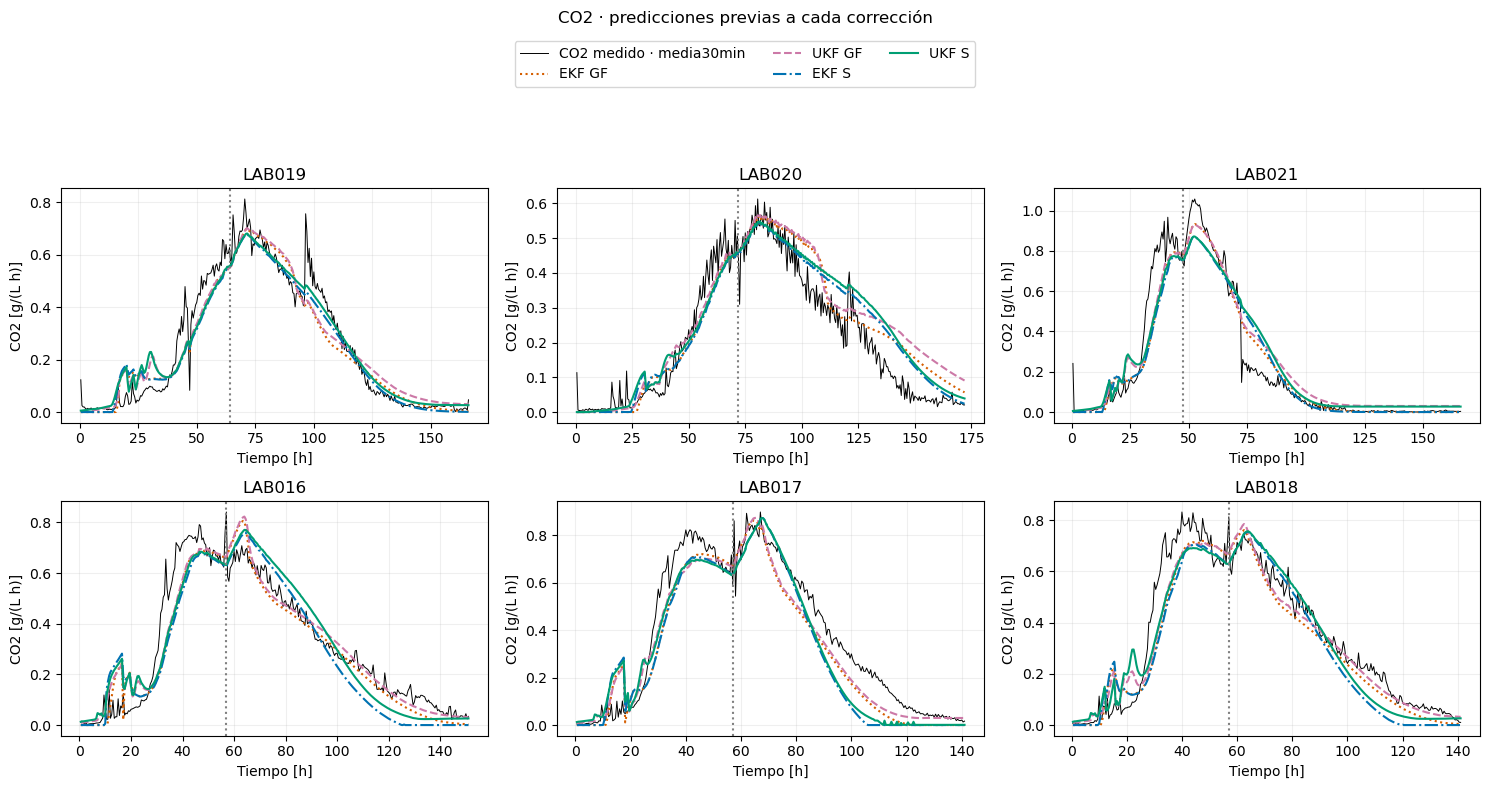

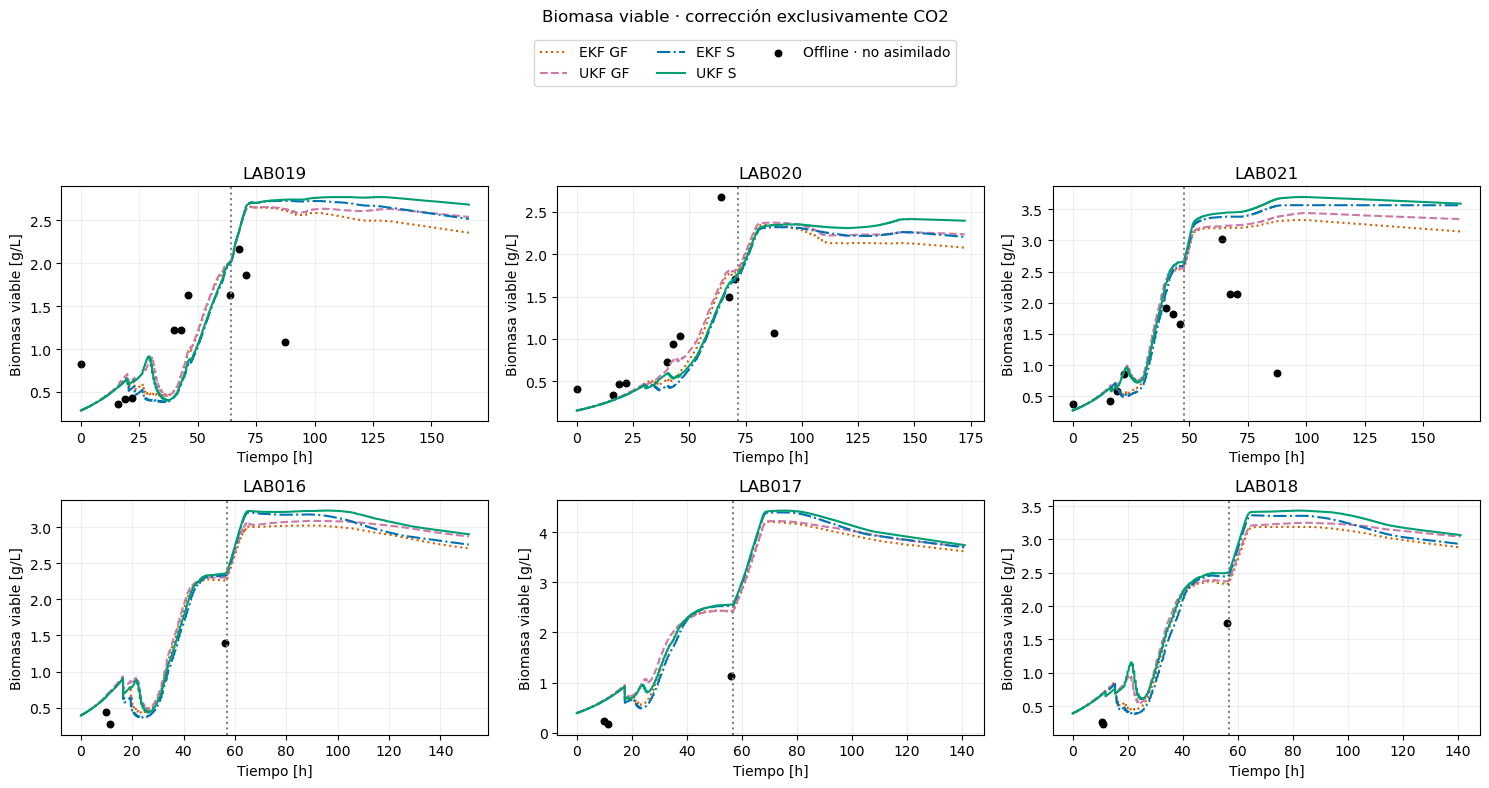

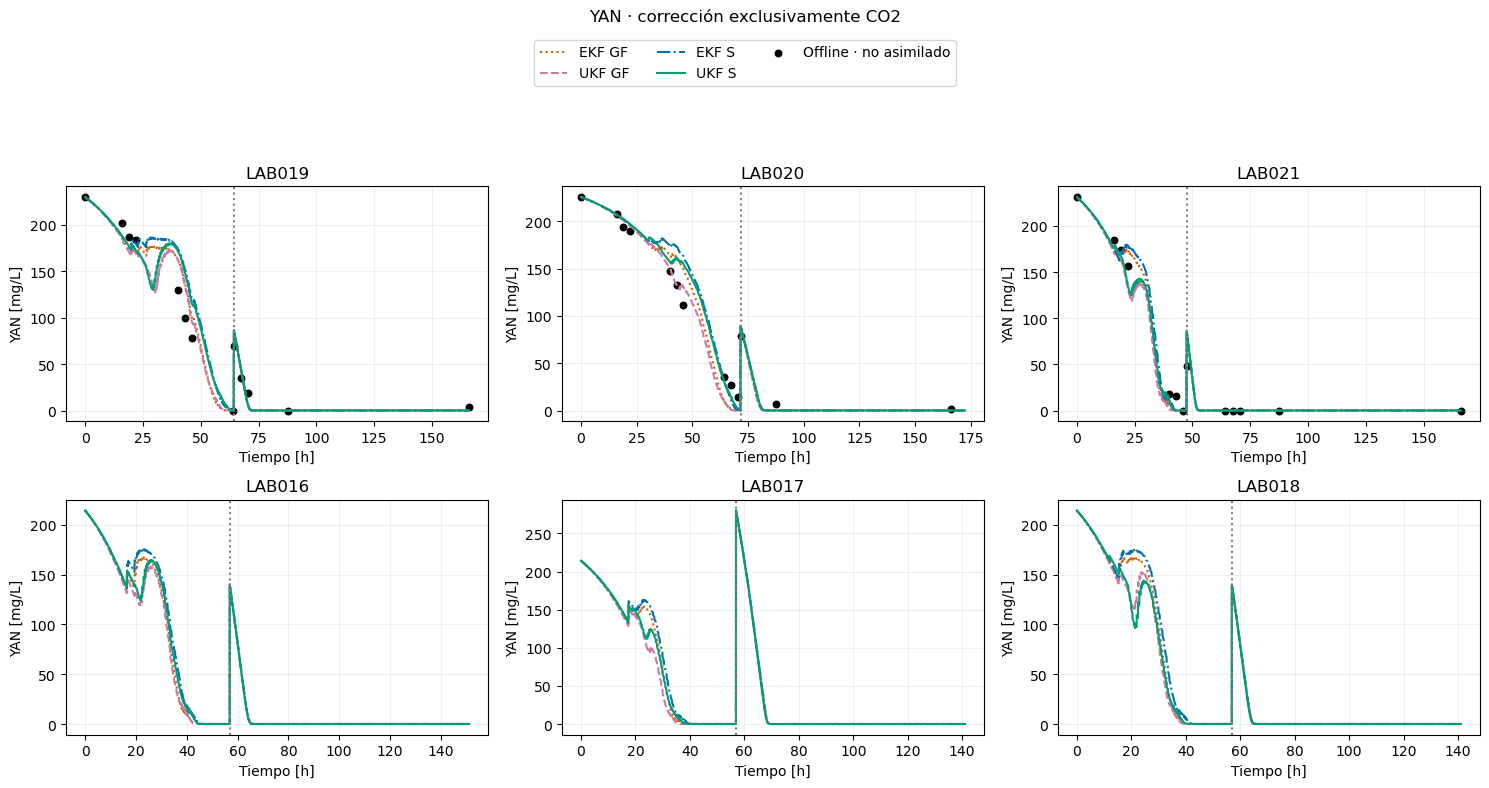

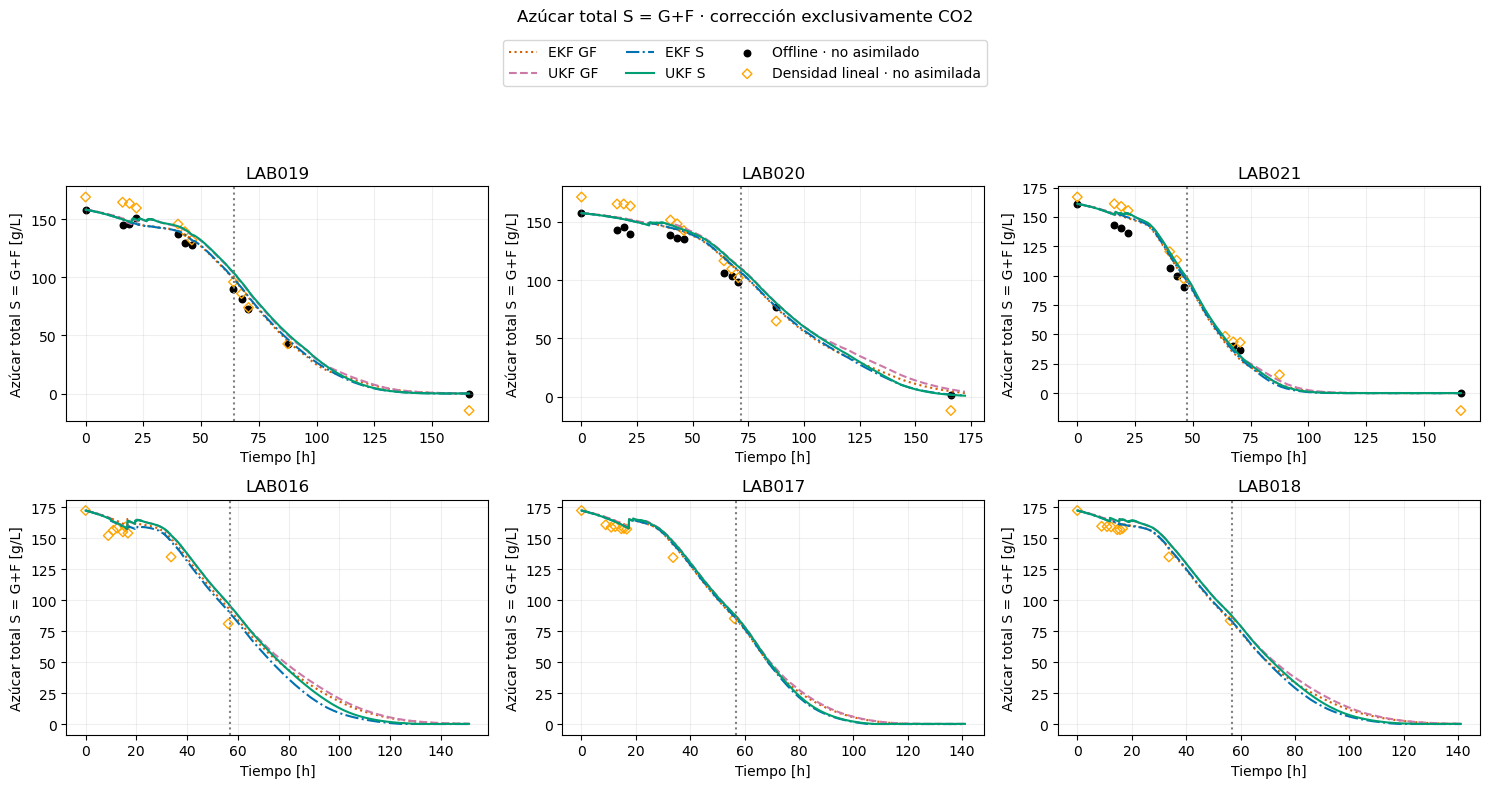

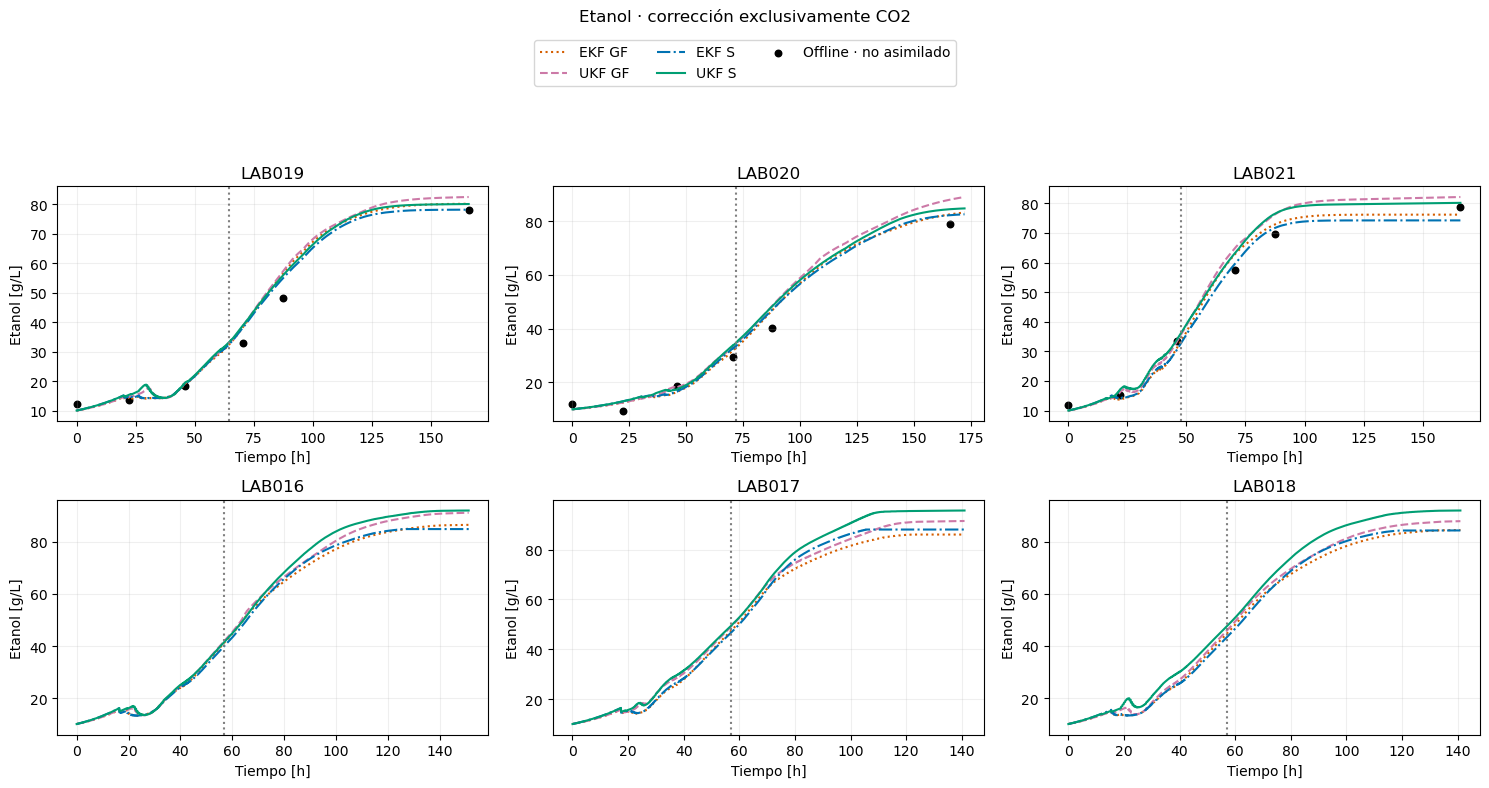

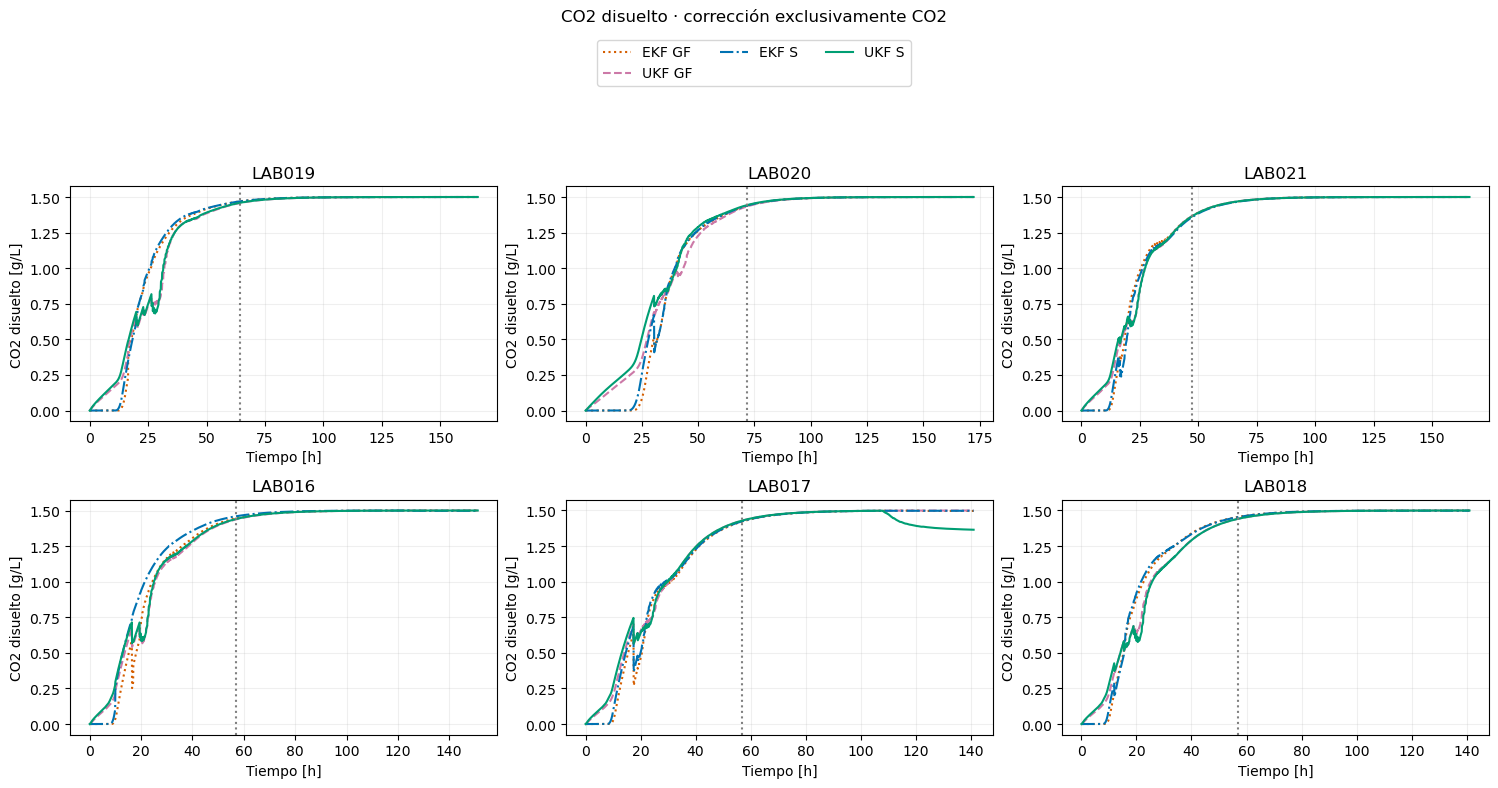

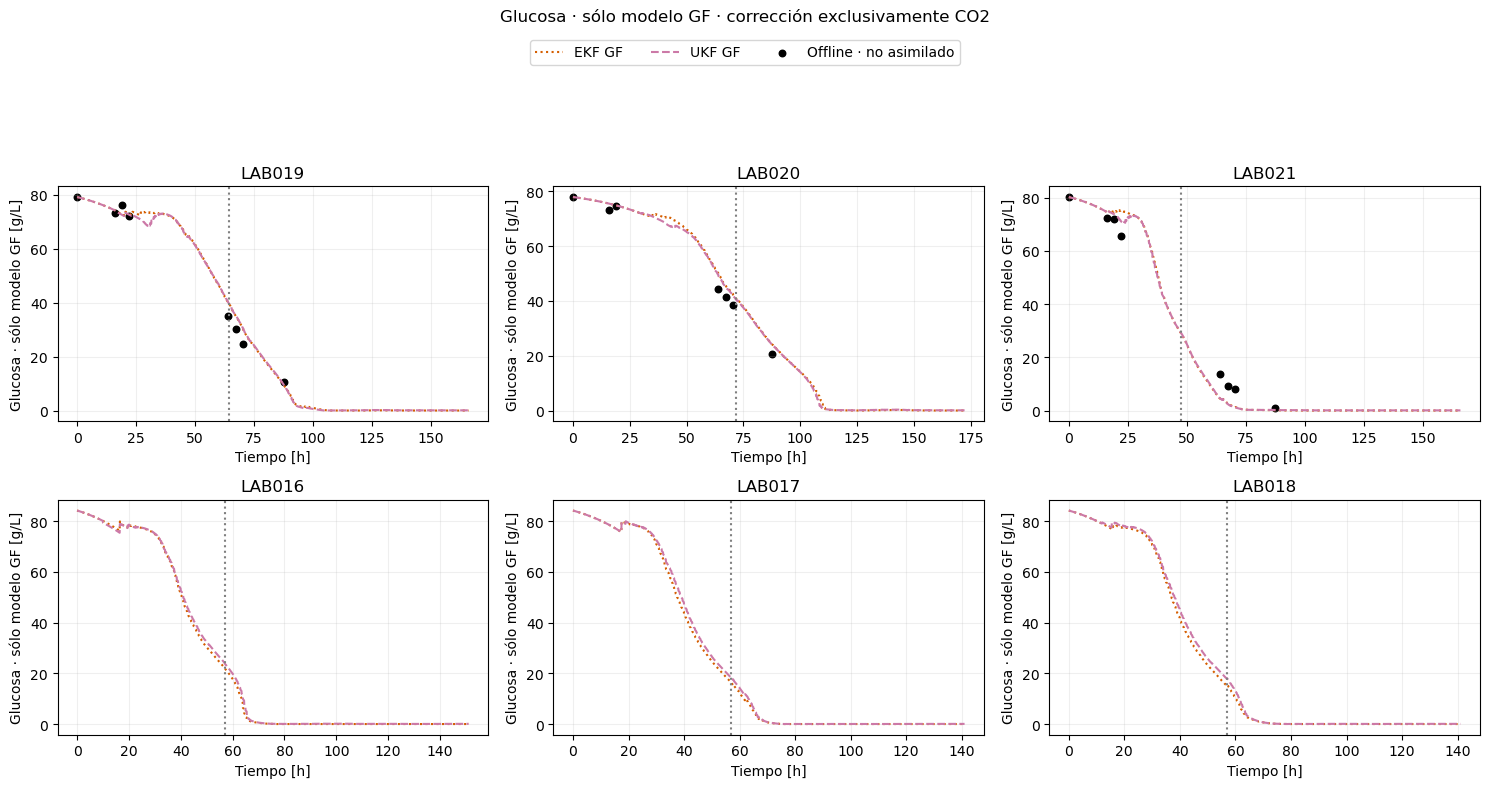

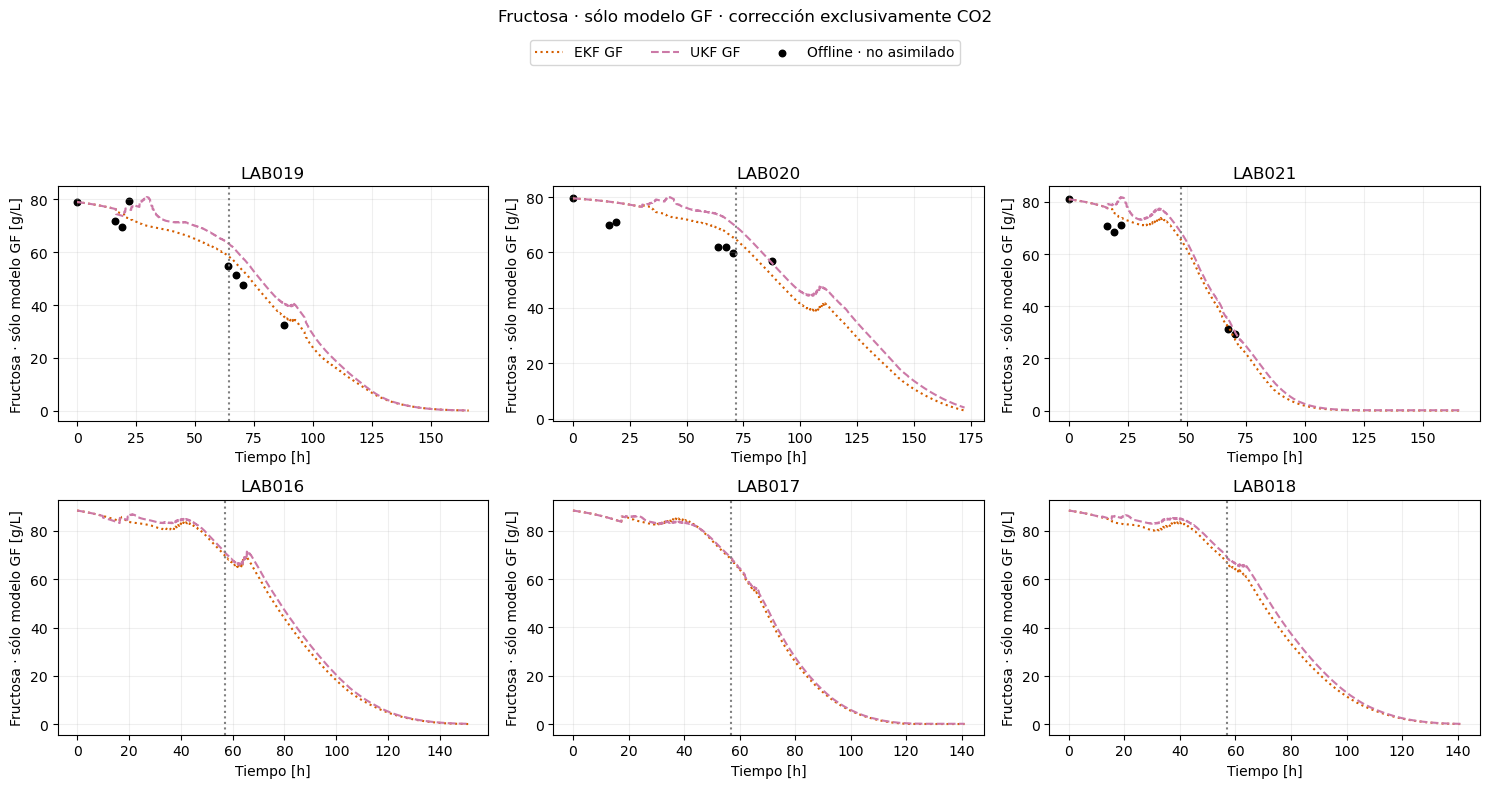

caso                    EKF GF      EKF S     UKF GF      UKF S
LAB    variable n                                              
LAB016 CO2      302   0.077763   0.100980   0.074179   0.090979
       X        3     0.573817   0.606620   0.597485   0.619247
LAB017 CO2      282   0.095960   0.117079   0.083515   0.106372
       X        3     0.837545   0.891501   0.846067   0.906447
LAB018 CO2      282   0.081000   0.096406   0.070627   0.083383
       X        3     0.496593   0.539279   0.513649   0.561193
LAB019 CO2      332   0.070047   0.063081   0.070248   0.061481
       E        5     4.544650   3.830410   5.206207   4.488298
       F        7     4.822322        NaN   7.338231        NaN
       G        7     3.522472        NaN   3.628858        NaN
       GF       10    6.385912   6.649437   9.725250  10.090105
       N        11   18.782831  25.477593  18.263220  23.831533
       X        10    0.665418   0.723219   0.667836   0.721917
LAB020 CO2      344   0.066492   0.065001   0.078580   0.071554
       E        5     3.810400   3.977969   5.865334   4.965911
       F        6     6.509513        NaN   8.890885        NaN
       G        6     3.658987        NaN   3.338175        NaN
       GF       11    8.524821   8.559756  10.944978  10.190903
       N        11   19.221317  22.362324  13.166577  17.253438
       X        10    0.574608   0.615821   0.550689   0.600298
LAB021 CO2      332   0.085678   0.102021   0.090855   0.104403
       E        5     3.327612   2.847877   4.737395   4.153513
       F        5     4.817355        NaN   7.679280        NaN
       G        7     6.352292        NaN   5.554615        NaN
       GF       9     8.711734   9.028853  10.375068  10.562848
       N        11    9.021143   8.866086  11.315895   8.700988
       X        10    0.987224   1.093828   1.014231   1.146638

,LAB,caso,actualizaciones,NIS_medio,componentes_recortados,updates_con_recorte
0,LAB019,EKF GF,217,1.614145,76,54
1,LAB019,UKF GF,217,1.628714,0,0
2,LAB019,EKF S,217,1.241845,61,61
3,LAB019,UKF S,217,1.221191,0,0
4,LAB020,EKF GF,223,1.174749,19,13
5,LAB020,UKF GF,223,1.476512,0,0
6,LAB020,EKF S,223,1.311405,9,9
7,LAB020,UKF S,223,1.610757,0,0
8,LAB021,EKF GF,166,3.423744,26,26
9,LAB021,UKF GF,166,3.784909,0,0


pasos_con_recorte  ...  max_correccion
modelo LAB    estado                         ...                
GF     LAB016 Acumulador                577  ...        0.028290
              Cd                        113  ...        0.017604
              F                          84  ...        0.022241
              G                         960  ...        1.165463
              N                        1211  ...        0.000558
       LAB017 Acumulador                599  ...        0.028709
              Cd                        114  ...        0.030205
              F                         268  ...        0.052895
              G                         821  ...        0.085016
              N                        1149  ...        0.001730
       LAB018 Acumulador                535  ...        0.028157
              Cd                        115  ...        0.020160
              F                          78  ...        0.021193
              G                         827  ...        0.086307
              N                        1147  ...        0.002298
       LAB019 Acumulador                783  ...        0.028600
              Cd                        166  ...        0.009334
              F                         151  ...        0.026861
              G                         762  ...        0.279611
              N                        1208  ...        0.000550
       LAB020 Acumulador                601  ...        0.019415
              Cd                        289  ...        0.006211
              G                         620  ...        0.916544
              N                        1179  ...        0.000892
       LAB021 Acumulador                952  ...        0.028500
              Cd                        147  ...        0.012654
              F                         638  ...        0.054578
              G                         969  ...        0.053154
              N                        1459  ...        0.001720
S      LAB016 Acumulador                610  ...        0.027894
              Cd                         97  ...        0.019697
              GF                        298  ...        0.104854
              N                        1183  ...        0.000310
       LAB017 Acumulador                633  ...        0.028083
              Cd                        486  ...        0.036304
              GF                        431  ...        0.159842
              N                        1102  ...        0.000389
       LAB018 Acumulador                566  ...        0.027635
              Cd                         97  ...        0.020101
              GF                        267  ...        0.090423
              N                        1129  ...        0.000841
       LAB019 Acumulador                755  ...        0.027010
              Cd                        153  ...        0.010814
              GF                        273  ...        0.074368
              N                        1150  ...        0.000308
       LAB020 Acumulador                647  ...        0.024707
              Cd                        262  ...        0.008124
              N                        1122  ...        0.000861
       LAB021 Acumulador                952  ...        0.026814
              Cd                        142  ...        0.010812
              GF                        727  ...        0.108528
              N                        1428  ...        0.000317

[52 rows x 4 columns]

max_cambio_media  max_cambio_cov
modelo LAB                                     
GF     LAB016          0.006537        0.013762
       LAB017          0.010919        0.023253
       LAB018          0.007394        0.016474
       LAB019          0.006299        0.004560
       LAB020          0.003850        0.003780
       LAB021          0.006342        0.006959
S      LAB016          0.008207        0.015093
       LAB017          0.015127        0.016245
       LAB018          0.008375        0.015397
       LAB019          0.004984        0.003539
       LAB020          0.003898        0.004300
       LAB021          0.004984        0.003433

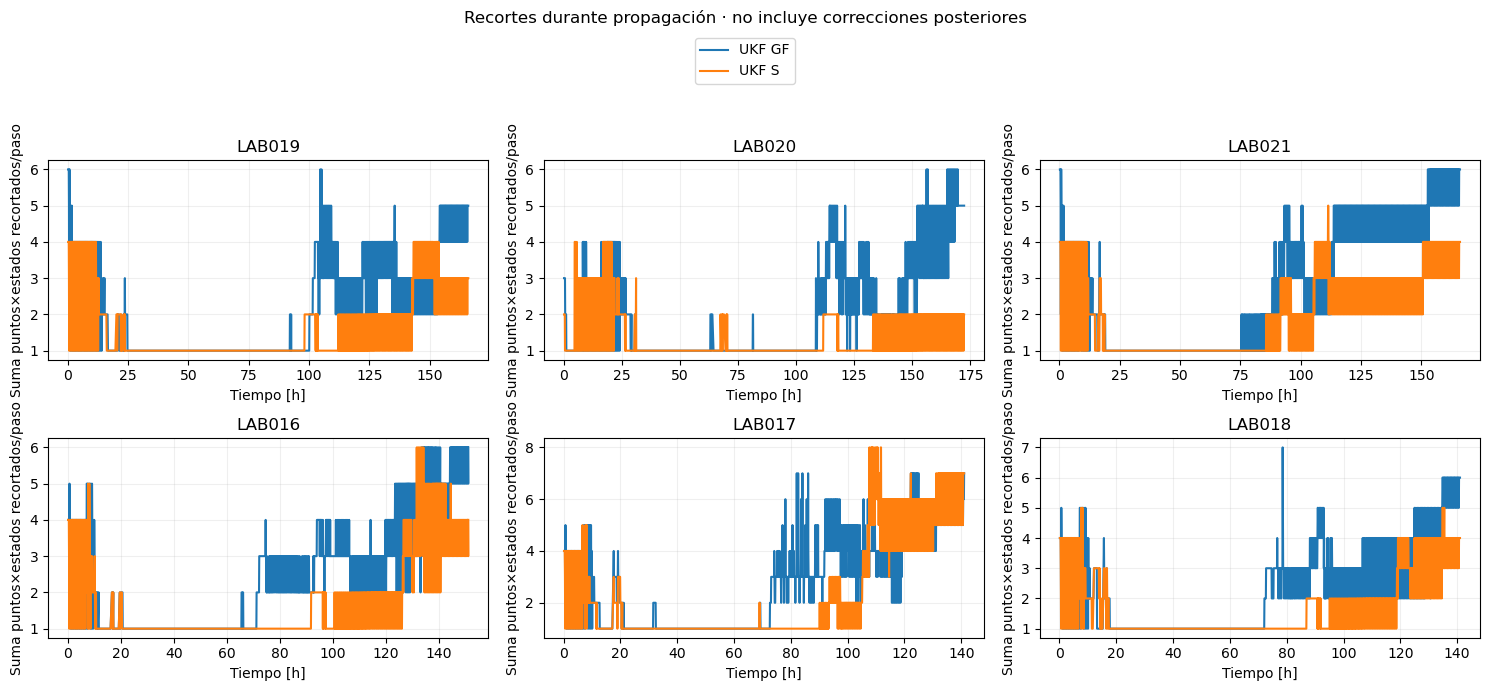

In [5]:

CASES={'EKF GF':RESULTS_GF,'UKF GF':UKF_GF,'EKF S':RESULTS_S,'UKF S':UKF_S}
COLORS={'EKF GF':'#D55E00','UKF GF':'#CC79A7','EKF S':'#0072B2','UKF S':'#009E73'}
STYLES={'EKF GF':':','UKF GF':'--','EKF S':'-.','UKF S':'-'}
metrics=[];diagnostics=[]
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,lab in zip(axs.flat,LABS):
 sensor=RESULTS_S[lab]['sensor'];ax.plot(sensor.t_h,sensor.measured,c='black',lw=.7,label='CO2 medido · media30min')
 for name,res in CASES.items():
  q=res[lab]['sensor'];assert np.allclose(q.measured,sensor.measured,equal_nan=True) and np.array_equal(q.assimilate,sensor.assimilate)
  ax.plot(q.t_h,q.forecast,color=COLORS[name],ls=STYLES[name],label=name)
  mask=q.valid&np.isfinite(q.measured);error=q.loc[mask,'forecast']-q.loc[mask,'measured'];metrics.append(dict(LAB=lab,variable='CO2',caso=name,n=int(mask.sum()),RMSE=float(np.sqrt(np.mean(error**2)))))
  d=res[lab]['diag'];diagnostics.append(dict(LAB=lab,caso=name,actualizaciones=len(d),NIS_medio=float(d.NIS.mean()),componentes_recortados=int(d.recortes.sum()),updates_con_recorte=int(d.recortes.gt(0).sum())))
 ax.axvline(batches[lab].pulses['N'][0][0],c='gray',ls=':');ax.set(title=lab,xlabel='Tiempo [h]',ylabel='CO2 [g/(L h)]');ax.grid(alpha=.2)
fig.suptitle('CO2 · predicciones previas a cada corrección');fig.legend(*axs.flat[0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=3);fig.tight_layout(rect=(0,0,1,.84));plt.show()
for state,title,factor in [('X','Biomasa viable',1),('N','YAN',1000),('GF','Azúcar total S = G+F',1),('E','Etanol',1),('Cd','CO2 disuelto',1),('G','Glucosa · sólo modelo GF',1),('F','Fructosa · sólo modelo GF',1)]:
 fig,axs=plt.subplots(2,3,figsize=(15,8));legend={}
 for ax,lab in zip(axs.flat,LABS):
  selected={k:v for k,v in CASES.items() if state not in ['G','F'] or k.endswith('GF')}
  for name,res in selected.items():
   f=res[lab]['frame'];ax.plot(f.t_h,f['EKF_'+state]*factor,color=COLORS[name],ls=STYLES[name],label=name)
  if state!='Cd':
   if lab in TRAIN:
    o=chemical_observations(v.chem,lab,state);tt=o.t_h.to_numpy();yy=o[CHEMICAL_COLUMNS[state]].to_numpy()
   elif state=='X':
    o=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=o.t_h.to_numpy();yy=o.X_viable_g_l.to_numpy()
   else:tt=np.array([]);yy=np.array([])
   if len(tt):
    ax.scatter(tt,yy*factor,c='black',s=22,label='Offline · no asimilado');mask=(tt>0)&(tt<=v.horizons[lab])
    if lab in TRAIN:
     if 'is_NUT'in o:mask &= ~o.is_NUT.astype(str).str.lower().eq('true').to_numpy()
     if state=='GF' and 'GF_zero_substitution'in o:mask &= ~o.GF_zero_substitution.astype(str).str.lower().eq('true').to_numpy()
    for name,res in selected.items():
     f=res[lab]['frame'];error=(np.interp(tt[mask],f.t_h,f['EKF_'+state])-yy[mask])*factor
     if len(error):metrics.append(dict(LAB=lab,variable=state,caso=name,n=len(error),RMSE=float(np.sqrt(np.mean(error**2)))))
   if state=='GF':
    o=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']);ax.scatter(o.t_h,2.5*(o.density_g_l-1000),marker='D',facecolors='none',edgecolors='orange',s=24,label='Densidad lineal · no asimilada')
  ax.axvline(batches[lab].pulses['N'][0][0],c='gray',ls=':');ax.set(title=lab,xlabel='Tiempo [h]',ylabel=title+(' [mg/L]' if state=='N' else ' [g/L]'));ax.grid(alpha=.2)
  for h,l in zip(*ax.get_legend_handles_labels()):legend[l]=h
 fig.suptitle(title+' · corrección exclusivamente CO2');fig.legend(legend.values(),legend.keys(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=3);fig.tight_layout(rect=(0,0,1,.84));plt.show()
metrics=pd.DataFrame(metrics);diagnostics=pd.DataFrame(diagnostics)
display(metrics.pivot(index=['LAB','variable','n'],columns='caso',values='RMSE'));display(diagnostics)
print('METRICS_JSON',metrics.to_json(orient='records'));print('DIAGNOSTICS_JSON',diagnostics.to_json(orient='records'))
sigma_log=pd.DataFrame(SIGMA_LOG);update_log=pd.DataFrame(UPDATE_LOG);projection_log=pd.DataFrame(PROJECTION_LOG)
display(sigma_log.groupby(['modelo','LAB','estado']).agg(pasos_con_recorte=('t_fin_h','size'),puntos_recortados=('puntos_recortados','sum'),eventos_etapas=('eventos_etapas','sum'),max_correccion=('max_correccion_unidad_fisica','max')))
display(projection_log.groupby(['modelo','LAB']).agg(max_cambio_media=('cambio_media_escalada','max'),max_cambio_cov=('cambio_cov_escalada','max')))
for suffix,frame in [('sigma_clips',sigma_log),('posterior_clips',update_log),('projection_changes',projection_log)]:
 path=ROOT/'notebooks/EKF'/f'{NAME}.{suffix}.csv';frame.to_csv(path,index=False);print('Registro',path)
fig,axs=plt.subplots(2,3,figsize=(15,7))
for ax,lab in zip(axs.flat,LABS):
 for model in ['GF','S']:
  z=sigma_log.loc[sigma_log.LAB.eq(lab)&sigma_log.modelo.eq(model)].groupby('t_fin_h').puntos_recortados.sum();ax.plot(z.index,z.values,label='UKF '+model)
 ax.set(title=lab,xlabel='Tiempo [h]',ylabel='Suma puntos×estados recortados/paso');ax.grid(alpha=.2)
fig.suptitle('Recortes durante propagación · no incluye correcciones posteriores');fig.legend(*axs.flat[0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.95));fig.tight_layout(rect=(0,0,1,.86));plt.show()
# Regresión de los dos EKF frente a la ejecución03 previa.
expected={'EKF GF':[.070046655,.066491978,.0856779359,.077762531,.0959595483,.0810001843],'EKF S':[.0630814324,.065001463,.1020209526,.100979786,.1170787098,.0964058926]}
for name,target in expected.items():
 values=metrics.loc[metrics.caso.eq(name)&metrics.variable.eq('CO2'),'RMSE'].to_numpy();assert np.max(abs(values-target))<1e-7
assert theta==BASE_THETA and (KLA,GAIN)==BASE_GAS and PS['Kie0']==theta['Kie0']
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in hashes.items())
print('Cuatro filtros completados; EKF previos reproducidos, mismas mediciones, PSD verificada, ningún dato offline asimilado ni archivo previo modificado.')


## Lectura de resultados
Las cuatro combinaciones terminaron. Los dos EKF reproducen los resultados previos con tolerancia1e-7 en RMSE CO2. Misma señal, ventanas, criterio de actualización, entradas y modelos congelados.

RMSE CO2 previo a corrección, g/(L h):

| LAB | EKF G/F | UKF G/F | EKF S | UKF S |
|---|---:|---:|---:|---:|
|019|.07005|.07025|.06308|.06148|
|020|.06649|.07858|.06500|.07155|
|021|.08568|.09085|.10202|.10440|
|016|.07776|.07418|.10098|.09098|
|017|.09596|.08351|.11708|.10637|
|018|.08100|.07063|.09641|.08338|

UKF mejora CO2 en016–018 para ambos modelos; en019 sólo mejora S. En020/021 empeora. El promedio de RMSE porLAB baja de.07949 a.07800(G/F) y.09076 a.08636(S), sin demostrar superioridad global.

Promedio de RMSE por ensayo con analítica disponible (X seis ensayos; N,S,E tres; no RMSE combinado entre variables):

| Variable | EKF G/F | UKF G/F | EKF S | UKF S |
|---|---:|---:|---:|---:|
| S, g/L |7.874|10.348|8.079|10.281|
| E, g/L |3.894|5.270|3.552|4.536|
| N, mg/L |15.675|14.249|18.902|16.595|
| X, g/L |.689|.698|.745|.759|

Mejora media de YAN, pero empeoran azúcar total, etanol y ligeramente biomasa. El promedio no implica mejora de cadaLAB. No se selecciona UKF sólo por seguir CO2.

Auditoría:33,032 filas de recortes de puntos sigma agregadas por modelo/LAB/paso/estado,1,180 filas de recortes posteriores por filtro/modelo/LAB/tiempo/estado. Reconciliados con contadores de las cuatro ejecuciones. UKF G/F no necesita recorte posterior; UKF S lo necesita en7 actualizaciones de017. Ambos proyectan frecuentemente puntos durante propagación, especialmente N, azúcar y acumulador. Los cambios de media/covarianza al proyectar se guardan por paso. Menos recortes posteriores no demuestra que las restricciones estén resueltas.

Tres registros CSV junto al notebook: `.sigma_clips.csv`, `.posterior_clips.csv`, `.projection_changes.csv`. Los conteos de proyección por etapa y puntos×estado no son número de fermentaciones ni de observaciones.

Comprobaciones: construcción de sigma/momentos y transformación afín con covarianza singular, PSD en cada paso, estados físicos dentro de límites tras proyección, mismas observaciones y actualizaciones, reproducción EKFprevios, archivos previos intactos, nueve figuras, SOURCE/EXECUTED válidos y sin errores. La proyección y las covarianzas siguen siendo aproximaciones; incertidumbres exploratorias, sin ajuste a ensayos reservados.

Referencia para puntos sigma: [Wan y van der Merwe, The Unscented Kalman Filter for Nonlinear Estimation](https://groups.seas.harvard.edu/courses/cs281/papers/unscented.pdf).
